Q1. Student Performance and Correlation Analysis

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

(a) Scatter plots and Pearson correlation

Study Hours vs Marks: 0.997942
Attendance vs Marks: 0.995727


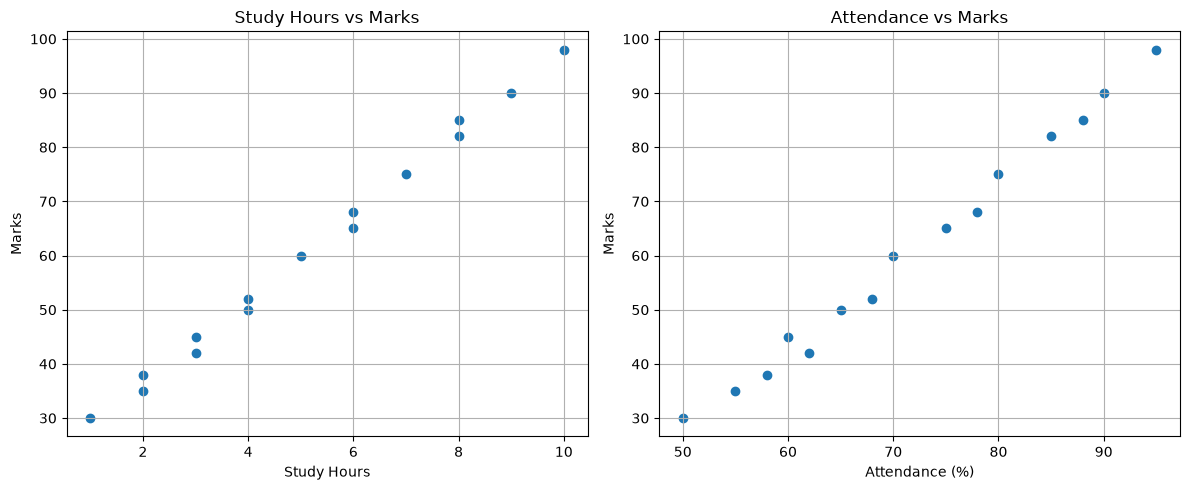

In [3]:
df = pd.DataFrame({"Study_Hours": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 2, 4, 6, 8, 3],
    "Attendance": [50, 55, 60, 65, 70, 75, 80, 85, 90, 95, 58, 68, 78, 88, 62],
    "Marks": [30, 35, 45, 50, 60, 65, 75, 82, 90, 98, 38, 52, 68, 85, 42]
})

r1 = np.corrcoef(df["Study_Hours"], df["Marks"])[0, 1]
r2 = np.corrcoef(df["Attendance"], df["Marks"])[0, 1]

print("Study Hours vs Marks:", round(r1, 6))
print("Attendance vs Marks:", round(r2, 6))

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(df["Study_Hours"], df["Marks"])
plt.xlabel("Study Hours")
plt.ylabel("Marks")
plt.title("Study Hours vs Marks")
plt.grid(True)

plt.subplot(1, 2, 2)
plt.scatter(df["Attendance"], df["Marks"])
plt.xlabel("Attendance (%)")
plt.ylabel("Marks")
plt.title("Attendance vs Marks")
plt.grid(True)

plt.tight_layout()
plt.show()


(b) Add a hypothetical student and recalculate correlation

Updated Study Hours vs Marks: 0.701197
Updated Attendance vs Marks: 0.996358


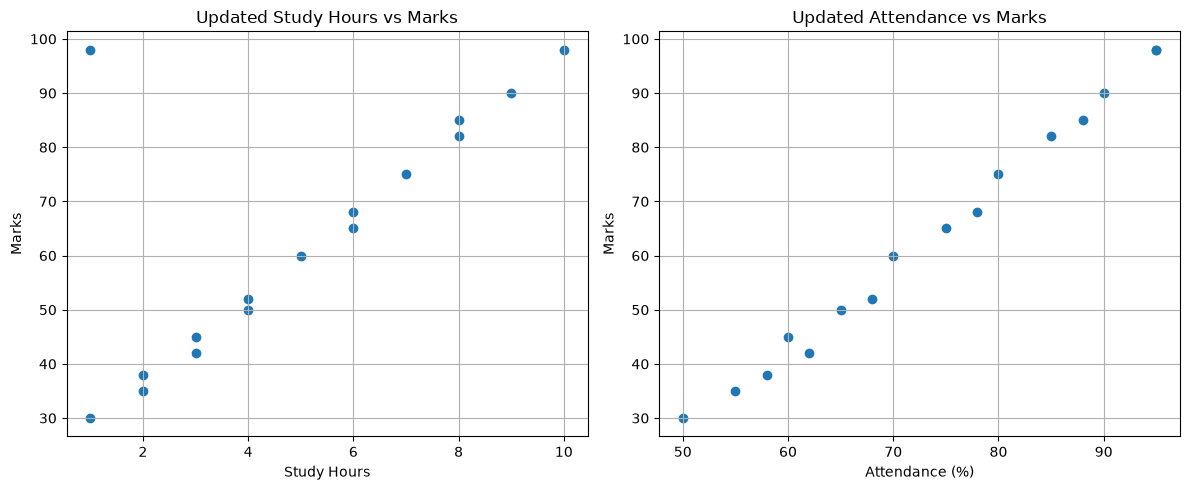

In [4]:
new_student = pd.DataFrame({"Study_Hours": [1],"Attendance": [95],"Marks": [98]})

updated_df = pd.concat([df, new_student], ignore_index=True)

new_r1 = np.corrcoef(updated_df["Study_Hours"],updated_df["Marks"])[0, 1]

new_r2 = np.corrcoef(updated_df["Attendance"],updated_df["Marks"])[0, 1]

print("Updated Study Hours vs Marks:",
     round(new_r1, 6))

print("Updated Attendance vs Marks:",
      round(new_r2, 6))

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(updated_df["Study_Hours"],
            updated_df["Marks"])
plt.xlabel("Study Hours")
plt.ylabel("Marks")
plt.title("Updated Study Hours vs Marks")
plt.grid(True)

plt.subplot(1, 2, 2)
plt.scatter(updated_df["Attendance"],
            updated_df["Marks"])
plt.xlabel("Attendance (%)")
plt.ylabel("Marks")
plt.title("Updated Attendance vs Marks")
plt.grid(True)

plt.tight_layout()
plt.show()


Q2. Product Sales: Bar Plot and Business Decisions

(a) Compare Units Sold and Revenue by Product

Highest Units Sold: Mobile
Lowest Units Sold: Monitor
Highest Revenue: Laptop
Lowest Revenue: Keyboard

Revenue Contribution:
      Product  Revenue_Percentage
0      Laptop               39.86
1      Mobile               31.89
2      Tablet               10.63
3  Headphones                4.78
4     Monitor                9.30
5    Keyboard                3.54


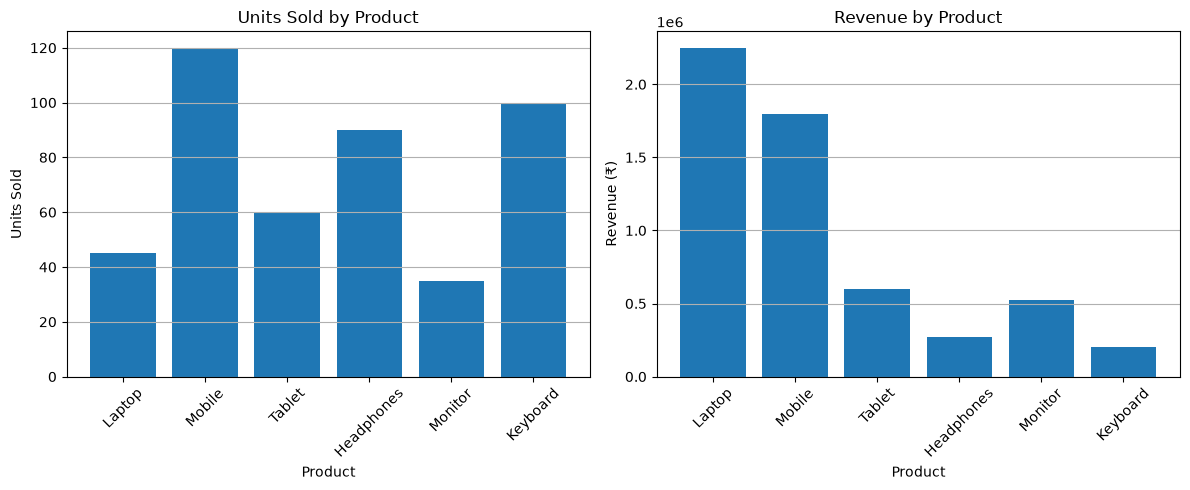

In [5]:
df = pd.DataFrame({"Product": ["Laptop", "Mobile", "Tablet","Headphones", "Monitor", "Keyboard"],
    "Units_Sold": [45, 120, 60, 90, 35, 100],
    "Revenue": [2250000, 1800000, 600000,
                270000, 525000, 200000]})

total_revenue = df["Revenue"].sum()

df["Revenue_Percentage"] = (df["Revenue"] / total_revenue) * 100

print("Highest Units Sold:",
      df.loc[df["Units_Sold"].idxmax(), "Product"])

print("Lowest Units Sold:",
      df.loc[df["Units_Sold"].idxmin(), "Product"])

print("Highest Revenue:",
      df.loc[df["Revenue"].idxmax(), "Product"])

print("Lowest Revenue:",
      df.loc[df["Revenue"].idxmin(), "Product"])

print("\nRevenue Contribution:")
print(df[["Product", "Revenue_Percentage"]]
      .round(2))

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.bar(df["Product"], df["Units_Sold"])
plt.title("Units Sold by Product")
plt.xlabel("Product")
plt.ylabel("Units Sold")
plt.xticks(rotation=45)
plt.grid(axis="y")

plt.subplot(1, 2, 2)
plt.bar(df["Product"], df["Revenue"])
plt.title("Revenue by Product")
plt.xlabel("Product")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=45)
plt.grid(axis="y")

plt.tight_layout()
plt.show()

(b) Revenue per Unit and Product Ranking

Revenue Per Unit Ranking:
      Product  Revenue_Per_Unit
0      Laptop           50000.0
1      Mobile           15000.0
4     Monitor           15000.0
2      Tablet           10000.0
3  Headphones            3000.0
5    Keyboard            2000.0

High Sales but Low Revenue Per Unit:
      Product  Units_Sold  Revenue_Per_Unit
3  Headphones          90            3000.0
5    Keyboard         100            2000.0


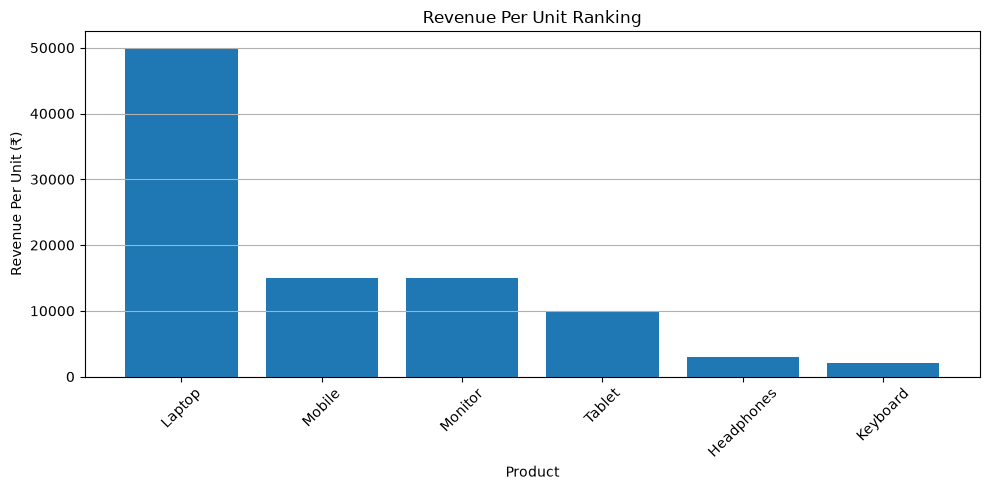

In [6]:
df["Revenue_Per_Unit"] = (df["Revenue"] / df["Units_Sold"])

ranking = df.sort_values(by="Revenue_Per_Unit",ascending=False)

print("Revenue Per Unit Ranking:")
print(ranking[["Product", "Revenue_Per_Unit"]])

high_sales = df[df["Units_Sold"] >= 90]

low_revenue_per_unit = high_sales[high_sales["Revenue_Per_Unit"] < 5000]

print("\nHigh Sales but Low Revenue Per Unit:")
print(low_revenue_per_unit[
    ["Product", "Units_Sold", "Revenue_Per_Unit"]
])

plt.figure(figsize=(10, 5))

plt.bar(ranking["Product"],ranking["Revenue_Per_Unit"])

plt.title("Revenue Per Unit Ranking")
plt.xlabel("Product")
plt.ylabel("Revenue Per Unit (₹)")
plt.xticks(rotation=45)
plt.grid(axis="y")
plt.tight_layout()
plt.show()


Q3. Correlation Investigation Using the Tips Dataset

(a) Scatter plots and Pearson correlation

Total Bill vs Tip: 0.675734
Size vs Tip: 0.489299


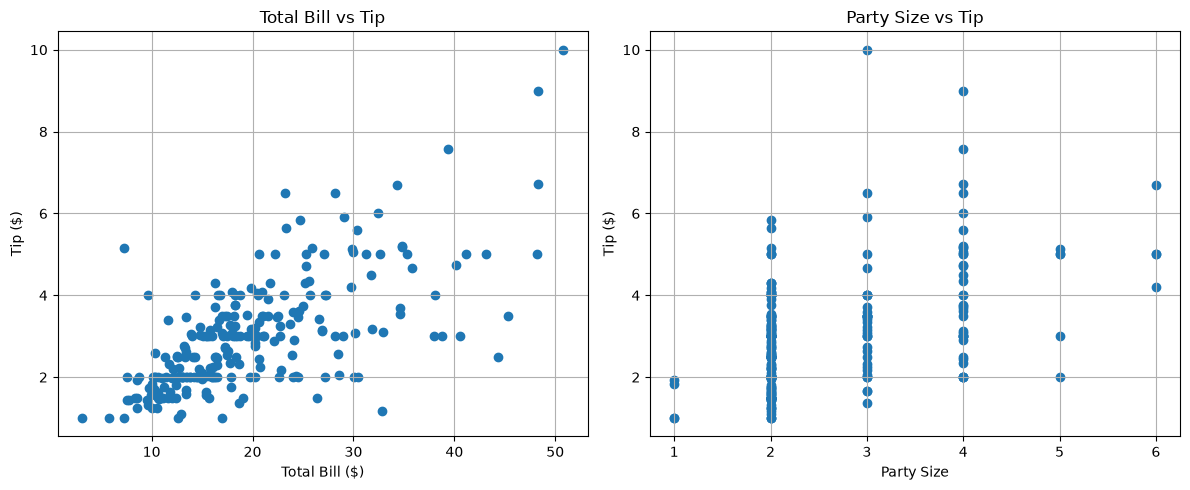

In [7]:
df = sns.load_dataset("tips")

r1 = np.corrcoef(df["total_bill"], df["tip"])[0, 1]

r2 = np.corrcoef(df["size"], df["tip"])[0, 1]

print("Total Bill vs Tip:", round(r1, 6))
print("Size vs Tip:", round(r2, 6))

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(df["total_bill"], df["tip"])
plt.xlabel("Total Bill ($)")
plt.ylabel("Tip ($)")
plt.title("Total Bill vs Tip")
plt.grid(True)

plt.subplot(1, 2, 2)
plt.scatter(df["size"], df["tip"])
plt.xlabel("Party Size")
plt.ylabel("Tip ($)")
plt.title("Party Size vs Tip")
plt.grid(True)

plt.tight_layout()
plt.show()


(b) Average tip by party size

Average Tip by Party Size:
size
1    1.438
2    2.582
3    3.393
4    4.135
5    4.028
6    5.225
Name: tip, dtype: float64


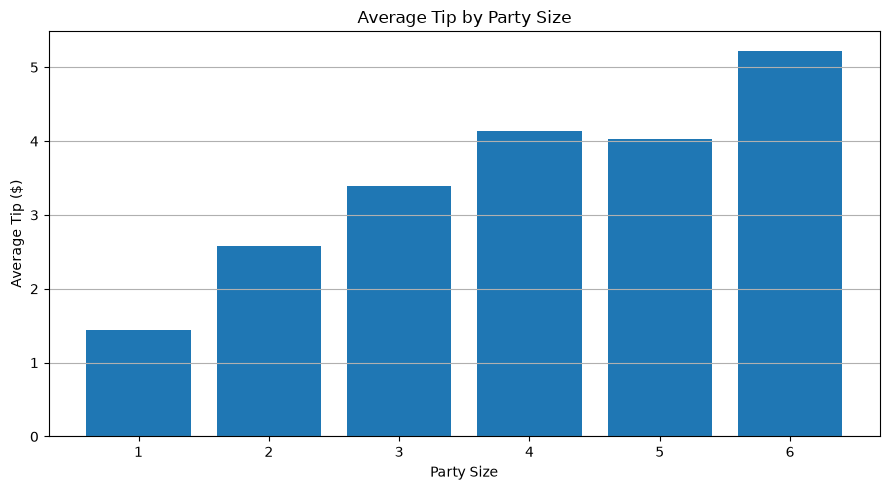

In [8]:
avg_tip = df.groupby("size")["tip"].mean()

print("Average Tip by Party Size:")
print(avg_tip.round(3))

plt.figure(figsize=(9, 5))

plt.bar(avg_tip.index.astype(str),avg_tip.values)

plt.xlabel("Party Size")
plt.ylabel("Average Tip ($)")
plt.title("Average Tip by Party Size")
plt.grid(axis="y")

plt.tight_layout()
plt.show()


Q4. Comparing Positive, Negative, and Weak Correlations

(a) Scatter plots and Pearson correlation

Advertising Cost vs Sales: -0.996452
Advertising Cost vs Customer Satisfaction: 0.088799


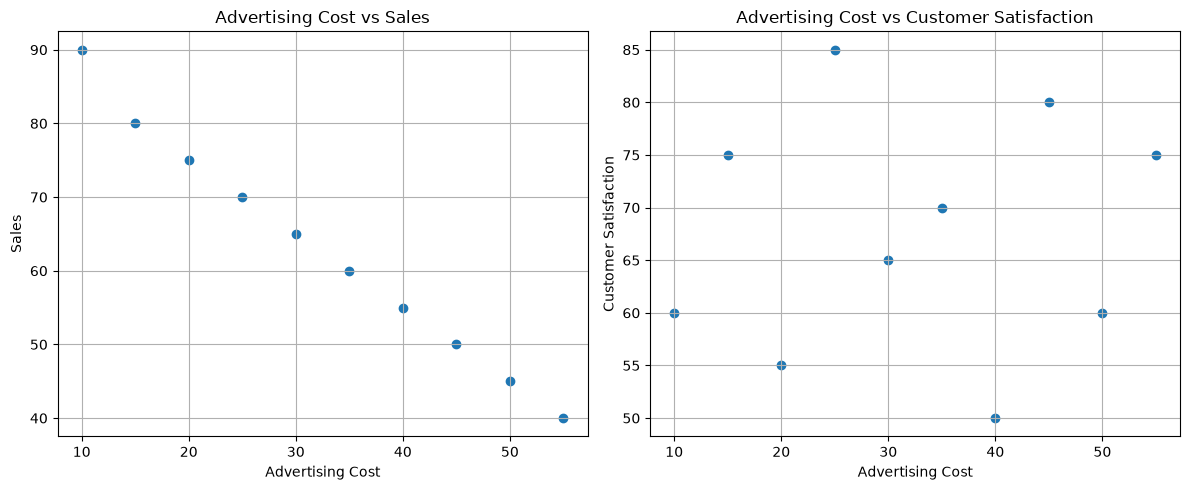

In [9]:
df = pd.DataFrame({"Campaign": ["A", "B", "C", "D", "E", "F", "G", "H", "I", "J"],
    "Advertising_Cost": [10, 15, 20, 25, 30, 35, 40, 45, 50, 55],
    "Sales": [90, 80, 75, 70, 65, 60, 55, 50, 45, 40],
    "Customer_Satisfaction": [60, 75, 55, 85, 65, 70, 50, 80, 60, 75]})

r1 = np.corrcoef(df["Advertising_Cost"], df["Sales"])[0, 1]

r2 = np.corrcoef(
    df["Advertising_Cost"],
    df["Customer_Satisfaction"]
)[0, 1]

print("Advertising Cost vs Sales:", round(r1, 6))
print("Advertising Cost vs Customer Satisfaction:", round(r2, 6))

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(df["Advertising_Cost"], df["Sales"])
plt.xlabel("Advertising Cost")
plt.ylabel("Sales")
plt.title("Advertising Cost vs Sales")
plt.grid(True)

plt.subplot(1, 2, 2)
plt.scatter(df["Advertising_Cost"],
            df["Customer_Satisfaction"])
plt.xlabel("Advertising Cost")
plt.ylabel("Customer Satisfaction")
plt.title("Advertising Cost vs Customer Satisfaction")
plt.grid(True)

plt.tight_layout()
plt.show()


(b) Add a new campaign and recalculate correlation

Updated Correlation: 0.568414


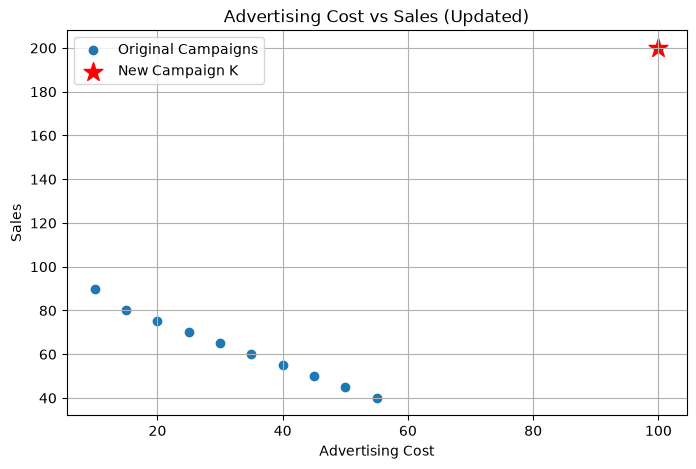

In [10]:
new_campaign = pd.DataFrame({"Campaign": ["K"],
    "Advertising_Cost": [100],
    "Sales": [200],
    "Customer_Satisfaction": [None]})


updated_df = pd.concat([df, new_campaign],ignore_index=True)
new_r = np.corrcoef(updated_df["Advertising_Cost"],updated_df["Sales"])[0, 1]

print("Updated Correlation:", round(new_r, 6))

plt.figure(figsize=(8, 5))

plt.scatter(df["Advertising_Cost"],df["Sales"],label="Original Campaigns")


plt.scatter( [100], [200],color="red",marker="*",s=200,label="New Campaign K")

plt.xlabel("Advertising Cost")
plt.ylabel("Sales")
plt.title("Advertising Cost vs Sales (Updated)")
plt.legend()
plt.grid(True)
plt.show()
